In [22]:
import numpy as np
import matplotlib.pyplot as plt

In [23]:
kB = 1.38e-23 #J/K

ref_sig = 3.05*1e-10
ref_eps = 79*kB
ref_mass = 2.6566962*1e-26

ref_time = np.sqrt(ref_mass*ref_sig*ref_sig/ref_eps)
print(ref_time)

1.505628052343374e-12


In [24]:
#Assuming LJ interaction between atoms of different CO2 molecules
#The lj parameters are defined from the TraPPE database (http://trappe.oit.umn.edu/)
sig_oo = 3.05*1e-10/ref_sig #Angstorms
eps_oo = 79*kB/ref_eps #Kelvin (eps/kB)
sig_cc = 2.8*1e-10/ref_sig #Angstorms
eps_cc = 27*kB/ref_eps #Kelvin (eps/kB)
#Using Lorentz-Berthelot mixing rules
sig_co = 0.5*(sig_oo + sig_cc)*1e-10/ref_sig
eps_co = ((eps_oo*eps_cc)**0.5)*kB/ref_eps
#partial charges
qc = 0.70 #e
qo = -0.35 #e

#Variables to speed up caclulations
sig6_oo = sig_oo**6
sig12_oo = sig_oo**12
sig6_cc = sig_cc**6
sig12_cc = sig_cc**12
sig6_co = sig_co**6
sig12_co = sig_co**12

kBT = 300*kB/ref_eps
dt = 0.0005*1e-12/ref_time #timestep of 0.5 femtosecond

num_particles = 100
num_units = 3*num_particles
rcut = 10*1e-10/ref_sig # (Angstorms)
rcut2 = rcut**2
L = 25*1e-10/ref_sig # (Angstorms)
bl = 1.16*1e-10/ref_sig # (Angstorms)

mass = np.array([[2.6566962*1e-26],[1.9944733*1e-26],[2.6566962*1e-26]]) #O C O in Kg
mass = mass/ref_mass
m = np.sum(mass)

I = 2*mass[0][0]*bl*bl*(np.array([[1, 0, 0],
                                  [0, 1, 0],
                                  [0, 0, 0]])) #Inertia in body fixed frame
Ixx = 2*mass[0][0]*bl*bl
red_I = I[0:2, 0:2]
I_inv = np.linalg.inv(red_I)

elec_factor = (9e9*1.6e-19*1.6e-19)/(ref_sig*ref_eps) #for electrostatic force calculation, convert charges into reduced units

In [25]:
def adjust_com(pos):
  r_com = np.sum(m*pos, axis=0)/(m*num_units)
  pos = pos - (r_com - [L/2, L/2, L/2])
  return pos

def quaternion_rotation_matrix(Q):
  q0, q1, q2, q3 = Q

  # First row of the rotation matrix
  r00 = q0*q0 + q1*q1 - q2*q2 - q3*q3
  r01 = 2 * (q1*q2 + q0*q3)
  r02 = 2 * (q1*q3 - q0*q2)

  # Second row of the rotation matrix
  r10 = 2 * (q1*q2 - q0*q3)
  r11 = q0*q0 - q1*q1 + q2*q2 - q3*q3
  r12 = 2 * (q2*q3 + q0*q1)

  # Third row of the rotation matrix
  r20 = 2 * (q1*q3 + q0*q2)
  r21 = 2 * (q2*q3 - q0*q1)
  r22 = q0*q0 - q1*q1 - q2*q2 + q3*q3

  rot_matrix = np.array([[r00, r01, r02],
                         [r10, r11, r12],
                         [r20, r21, r22]])

  return rot_matrix

def B_for_q_dot(Q):
  q0, q1, q2, q3 = Q

  B_matrix = 0.5*np.array([[q0, -q1, -q2, -q3],
                           [q1, q0, -q3, q2],
                           [q2, q3, q0, -q1],
                           [q3, -q2, q1, q0]])
  return B_matrix

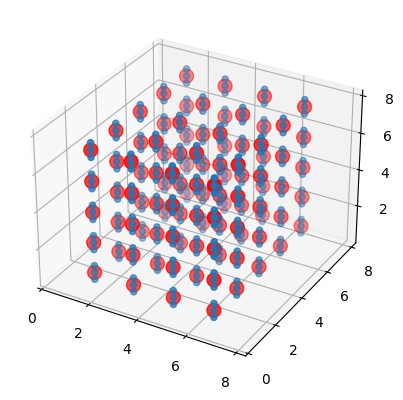

In [26]:
%matplotlib inline

pos = np.zeros((num_units,3)) #order of O C O
vel = np.zeros((num_units,3))

q = np.ones((num_particles, 4))*[1,0,0,0] #No rotation initially
q_dot = np.ones((num_particles, 4))*[0,0,0,0] #q_dot = B*ang_vel (4*4 * 4*1 --> 4*1)

ang_mom = np.zeros((num_particles, 3))
ang_vel = np.zeros((num_particles,4))

a = L/np.ceil((num_particles)**(1/3))
ip = 0

for x in range(int(L/a)):
  for y in range(int(L/a)):
    for z in range(int(L/a)):
      pos[ip:ip+3,0] = x*a
      pos[ip:ip+3,1] = y*a
      pos[ip,2] = z*a

      pos[ip+1,2] = pos[ip,2] + bl
      pos[ip+2,2] = pos[ip,2] + 2*bl

      ip+=3

      if ip==num_units: break
    if ip==num_units: break
  if ip==num_units: break

pos = adjust_com(pos)

pos_com = []
vel_com = []

for i in range(0,num_units,3):
  r_com = np.sum(pos[i:i+3]*mass, axis=0)/(np.sum(mass))
  pos_com.append(r_com)

for i in range(0,num_units,3):
  v_com = np.sum(vel[i:i+3]*mass, axis=0)/(np.sum(mass))
  vel_com.append(v_com)

pos_com = np.array(pos_com)
vel_com = np.array(vel_com)

fig = plt.figure()
ax = plt.axes(projection='3d')
ax.scatter3D(pos[:,0], pos[:,1], pos[:,2])
ax.scatter3D(pos_com[:,0], pos_com[:,1], pos_com[:,2],c='red',s=100)
plt.xlim(0,L)
plt.ylim(0,L)
plt.show()

In [27]:
def potij(mi, mj):
  Fi = np.zeros(3)
  torquei = np.zeros(3)
  torquej = np.zeros(3)
  Epot = 0

  for k in range(len(mi)):
    ri = mi[k] - mi[1]
    for l in range(len(mj)):
      rj = mj[l] - mj[1]
      distij = mj[l] - mi[k]

      #Periodic Boundary Condition
      distij[0] -= L*np.rint(distij[0]/L)
      distij[1] -= L*np.rint(distij[1]/L)
      distij[2] -= L*np.rint(distij[2]/L)

      distij2 = distij[0]**2 + distij[1]**2 + distij[2]**2
      temp = np.sqrt(distij2)
      if k==1 and l==1: #CC interaction
        A = 4*eps_cc*(12*(sig12_cc/distij2**7) - 6*(sig6_cc/distij2**4))
        els = elec_factor*qc*qc/(temp**3)

        forceijx = -A*distij[0] + els*distij[0]
        forceijy = -A*distij[1] + els*distij[1]
        forceijz = -A*distij[2] + els*distij[0]

        Epot += (4*eps_cc*((sig12_cc)/(distij2**6) - (sig6_cc)/(distij2**3))) + elec_factor*qc*qc/(temp)

      elif k==1 or l==1: #CO interaction
        A = 4*eps_co*(12*(sig12_co/distij2**7) - 6*(sig6_co/distij2**4))
        els = elec_factor*qo*qc/(temp**3)

        forceijx = -A*distij[0] + els*distij[0]
        forceijy = -A*distij[1] + els*distij[1]
        forceijz = -A*distij[2] + els*distij[0]

        Epot += (4*eps_co*((sig12_co)/(distij2**6) - (sig6_co)/(distij2**3))) + elec_factor*qo*qc/(temp)

      else: #OO interaction
        A = 4*eps_oo*(12*(sig12_oo/distij2**7) - 6*(sig6_oo/distij2**4))
        els = elec_factor*qo*qo/(temp**3)

        forceijx = -A*distij[0] + els*distij[0]
        forceijy = -A*distij[1] + els*distij[1]
        forceijz = -A*distij[2] + els*distij[0]

        Epot += (4*eps_oo*((sig12_oo)/(distij2**6) - (sig6_oo)/(distij2**3))) + elec_factor*qo*qo/(temp)

      Fi += [forceijx, forceijy, forceijz]
      torquei += np.cross(ri, [forceijx, forceijy, forceijz])
      torquej += np.cross(rj, [-forceijx, -forceijy, -forceijz])

  return Epot, Fi, torquei, torquej

def hamilton_product(q1, q2): #Hamilton product of two quaternions
    w1, x1, y1, z1 = q1
    w2, x2, y2, z2 = q2
    return np.array([
        w1*w2 - x1*x2 - y1*y2 - z1*z2,
        w1*x2 + x1*w2 + y1*z2 - z1*y2,
        w1*y2 - x1*z2 + y1*w2 + z1*x2,
        w1*z2 + x1*y2 - y1*x2 + z1*w2
    ])

def generate_new_pos(q,pos_v):
  pos_v = [0, pos_v[0], pos_v[1], pos_v[2]]
  temp = hamilton_product(q, pos_v)
  q_conj = [q[0], -q[1], -q[2], -q[3]]
  new_pos_v = hamilton_product(temp, q_conj)[1:4]
  mag = np.linalg.norm(new_pos_v)

  return mag, new_pos_v

# **Thermalize the system**

In [28]:
gammat = 5*1e12*ref_time #damping constant (inverse time)
gammar = 3*1e12*ref_time #damping constant (inverse time)
dt = 0.0005*1e-12/ref_time #timestep of 0.25 femtosecond
total_timesteps = 1000
vel_every_20 = []
for it in range(total_timesteps):
  F = np.zeros([num_particles, 3]) #force on com
  torque = np.zeros([num_particles, 3]) #torque about com
  Epot = 0
  for i in range(num_particles):
    for j in range(i+1, num_particles):
      distij = pos_com[j] - pos_com[i]

      #Periodic Boundary Condition
      distij[0] -= L*np.rint(distij[0]/L)
      distij[1] -= L*np.rint(distij[1]/L)
      distij[2] -= L*np.rint(distij[2]/L)

      distij2 = distij[0]**2 + distij[1]**2 + distij[2]**2

      if distij2 < rcut2:
        mi = [pos[3*i], pos[3*i+1], pos[3*i+2]]
        mj = [pos[3*j], pos[3*j+1], pos[3*j+2]]
        pot, force, torquei, torquej = potij(mi, mj)

        F[i] += force
        F[j] += (-1*force)

        torque[i] += torquei
        torque[j] += torquej

        Epot += pot

  #Langevin thermostat to regulate the temperature of the system
  F = F - m*gammat*vel_com + np.sqrt(2*m*gammat*kBT/dt)*np.random.normal(0,1,(num_particles,3))

  # Convert torque and angular momentum to body frame to apply thermostat using Inertia in body frame
  ang_mom_bf = np.zeros((num_particles, 3))
  for i in range(num_particles):
    A = quaternion_rotation_matrix(q[i])
    torque[i] = np.matmul(A, torque[i])
    ang_mom_bf[i] = np.matmul(A, ang_mom[i])

  random_torque = np.sqrt(2*Ixx*gammar*kBT/dt)*np.random.normal(0,1,(num_particles,3))
  random_torque[:,2] = 0 #Izz = 0, body can't have angular velocity around z-axis
  fric = gammar*ang_mom_bf
  fric[:,2] = 0 #Izz=0
  torque = torque - fric + random_torque
    
  #Convert torque back to space frame for further calculations
  for i in range(num_particles):
    A = quaternion_rotation_matrix(q[i])
    A_inv = np.linalg.inv(A)
    torque[i] = np.matmul(A_inv, torque[i])

  #Update velocity and position of com using standard leap-frog algorithm
  vel_com = vel_com + dt*(F/m)
  pos_com = pos_com + vel_com*dt

  v_com = np.sum(m*vel_com, axis=0)/(m*num_particles)
  vel_com = vel_com - (v_com)

  #Update angular momentum and quaternions using leap-frog rotational algorithm
  ang_mom_t = ang_mom + (dt/2)*torque #L(t)
  ang_mom_bf = np.zeros((num_particles,3))

  for i in range(num_particles):
    A = quaternion_rotation_matrix(q[i])
    ang_mom_bf[i] = np.matmul(A, ang_mom_t[i])

  ang_vel = np.zeros((num_particles,4))
  for i in range(num_particles):
    ang_vel[i][1:3] = np.matmul(I_inv, ang_mom_bf[i][0:2])
    B = B_for_q_dot(q[i])
    q_dot[i] = np.matmul(B, ang_vel[i])

  q_mid = q + (dt/2)*q_dot #initial prediction for q(t + dt/2)

  ang_mom = ang_mom + dt*torque #L(t + dt/2)
  ang_mom_bf = np.zeros((num_particles,3)) #switch to body frame

  for i in range(num_particles):
    A = quaternion_rotation_matrix(q_mid[i])
    ang_mom_bf[i] = np.matmul(A, ang_mom[i])

  ang_vel = np.zeros((num_particles,4))
  for i in range(num_particles):
    ang_vel[i][1:3] = np.matmul(I_inv, ang_mom_bf[i][0:2])
    B = B_for_q_dot(q[i])
    q_dot[i] = np.matmul(B, ang_vel[i]) #q_dot(t + dt/2)

  temp = np.ones(num_particles)
  q_dot_old = q_dot.copy()

  while all(temp>0.000001):
    for i in range(num_particles):
      B = B_for_q_dot(q_mid[i])
      q_dot[i] = np.matmul(B, ang_vel[i])

    q_mid = q + (dt/2)*q_dot
    temp = np.array([np.linalg.norm(q_dot[k]-q_dot_old[k])/np.linalg.norm(q_dot_old[k]) for k in range(num_particles)])
    q_dot_old = q_dot.copy()

  q = q + dt*q_dot #q(t + dt)

  for i in range(num_particles):
    pos_v = pos[3*i] - pos_com[i]
    mag, new_pos_v = generate_new_pos(q[i], pos_v)

    pos[3*i] = pos_com[i] + (bl/mag)*new_pos_v
    pos[3*i + 1] = pos_com[i]
    pos[3*i + 2] = pos_com[i] - (bl/mag)*new_pos_v

  Ekin_trans = 0.5*m*np.sum(vel_com*vel_com)
  Ekin_rot = 0.5*(Ixx)*np.sum(ang_vel*ang_vel) #As Ixx = Iyy, Izz=0 for CO2

  Ekin = Ekin_trans + Ekin_rot

  if it%50 == 0:
    vel_every_20.append(vel_com.copy())

  if it%100 == 0:
    print(it, "  ", Ekin_trans, "  ", Ekin_rot, "  ", Epot)
    for i in range(num_particles):
      q[i] = q[i]/np.linalg.norm(q[i])

0    2.731503968696316    1.1499394120111095    1376.796662817615
100    210.76121470200704    136.3346743211271    -349.4271224174298
200    332.8618052365792    187.82815707496312    -334.99332670743814
300    390.7543084020193    216.29916120426347    -311.2684535340782
400    431.1069571618196    240.23403283869254    -261.98064547047767
500    468.600934967075    285.81556533089764    -352.5605203377863
600    516.1455549366625    342.54834545273627    -90.91363053515022
700    569.6916945642276    347.8302400626069    -294.3354949373326
800    545.0124736297256    381.0013453122839    -217.15019885766367
900    754.7389403727033    412.3943808989261    -194.10150569913915


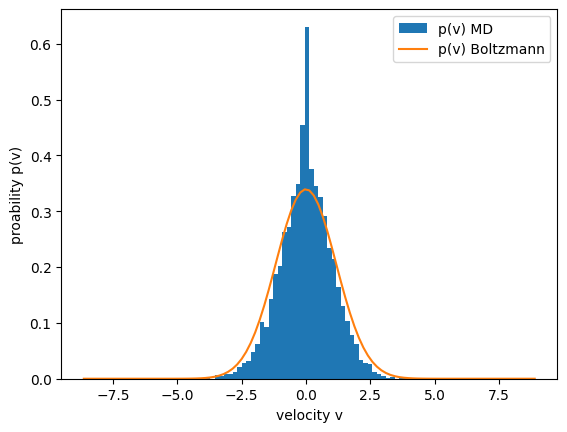

In [29]:
#Velocity Distribution and Potential Energy Distribution

nb = 100 # number of bins
counts, bins = np.histogram(vel_every_20, density=True, bins=nb)
plt.hist(bins[:-1], bins, weights=counts, label="p(v) MD") # plot histogram
plt.plot(bins, np.exp(-m/2 * (bins*bins)/kBT)/np.sqrt(2*np.pi*kBT/m),label="p(v) Boltzmann") # compare to Boltzmann distribution
plt.legend()
plt.xlabel("velocity v")
plt.ylabel("proability p(v)")
plt.show()

# If the simulated histogram matches the Boltzman prediction, then our MD algorithm works well and
# produces a statistically correct distribution of equilibrium states.

In [30]:
ang_mom_updated = ang_mom.copy()
q_updated = q.copy()
vel_com_updated = vel_com.copy()
pos_com_updated = pos_com.copy()
pos_updated = pos.copy()

In [32]:
ang_mom = ang_mom_updated
q = q_updated
vel_com = vel_com_updated
pos_com = pos_com_updated
pos = pos_updated

# **Production Run**

In [33]:
gammat = 5*1e12*ref_time #damping constant (inverse time)
gammar = 4*1e12*ref_time #damping constant (inverse time)
dt = 0.0005*1e-12/ref_time #timestep of 0.5 femtosecond
total_timesteps = 30000

# O-O RDF Calculation
binwidth = 0.05
nbins = int(L/2/binwidth) + 1
gr_col = np.zeros(nbins)
start = 100

pe = []
ke = []
ke_trans = []
ke_rot = []
pos_com_every_20 = []
pos_every_20 = []
vel_every_20 = []

for it in range(total_timesteps):
  F = np.zeros([num_particles, 3]) #force on com
  torque = np.zeros([num_particles, 3]) #torque about com
  Epot = 0
  check = (it >= start and it%100 == 0)

  for i in range(num_particles):
    for j in range(i+1, num_particles):
      distij = pos_com[j] - pos_com[i]

      #Periodic Boundary Condition
      distij[0] -= L*np.rint(distij[0]/L)
      distij[1] -= L*np.rint(distij[1]/L)
      distij[2] -= L*np.rint(distij[2]/L)

      distij2 = distij[0]**2 + distij[1]**2 + distij[2]**2
      if check:
        if distij2 < (L**2)/4 :
          rad = np.sqrt(distij2)
          ibin = int(np.floor(rad/binwidth))
          gr_col[ibin]+=(1/(4*np.pi*(distij2)*binwidth)) #per unit area (r to r+dr)
            
      if distij2 < rcut2:
        mi = [pos[3*i], pos[3*i+1], pos[3*i+2]]
        mj = [pos[3*j], pos[3*j+1], pos[3*j+2]]
        pot, force, torquei, torquej = potij(mi, mj)

        F[i] += force
        F[j] += (-1*force)

        torque[i] += torquei
        torque[j] += torquej

        Epot += pot

  #Langevin thermostat to regulate the temperature of the system
  F = F - m*gammat*vel_com + np.sqrt(2*m*gammat*kBT/dt)*np.random.normal(0,1,(num_particles,3))

  # Convert torque and angular momentum to body frame to apply thermostat using Inertia in body frame
  ang_mom_bf = np.zeros((num_particles, 3))
  for i in range(num_particles):
    A = quaternion_rotation_matrix(q[i])
    torque[i] = np.matmul(A, torque[i])
    ang_mom_bf[i] = np.matmul(A, ang_mom[i])

  random_torque = np.sqrt(2*Ixx*gammar*kBT/dt)*np.random.normal(0,1,(num_particles,3))
  random_torque[:,2] = 0 #Izz = 0, body can't have angular velocity around z-axis
  fric = gammar*ang_mom_bf
  fric[:,2] = 0 #Izz=0
  torque = torque - fric + random_torque
    
  #Convert torque back to space frame for further calculations
  for i in range(num_particles):
    A = quaternion_rotation_matrix(q[i])
    A_inv = np.linalg.inv(A)
    torque[i] = np.matmul(A_inv, torque[i])

  #Update velocity and position of com using standard leap-frog algorithm
  vel_com = vel_com + dt*(F/m)
  pos_com = pos_com + vel_com*dt

  v_com = np.sum(m*vel_com, axis=0)/(m*num_particles)
  vel_com = vel_com - (v_com)

  #Update angular momentum and quaternions using leap-frog rotational algorithm
  ang_mom_t = ang_mom + (dt/2)*torque #L(t)
  ang_mom_bf = np.zeros((num_particles,3))

  for i in range(num_particles):
    A = quaternion_rotation_matrix(q[i])
    ang_mom_bf[i] = np.matmul(A, ang_mom_t[i])

  ang_vel = np.zeros((num_particles,4))
  for i in range(num_particles):
    ang_vel[i][1:3] = np.matmul(I_inv, ang_mom_bf[i][0:2])
    B = B_for_q_dot(q[i])
    q_dot[i] = np.matmul(B, ang_vel[i])

  q_mid = q + (dt/2)*q_dot #initial prediction for q(t + dt/2)

  ang_mom = ang_mom + dt*torque #L(t + dt/2)
  ang_mom_bf = np.zeros((num_particles,3)) #switch to body frame

  for i in range(num_particles):
    A = quaternion_rotation_matrix(q_mid[i])
    ang_mom_bf[i] = np.matmul(A, ang_mom[i])

  ang_vel = np.zeros((num_particles,4))
  for i in range(num_particles):
    ang_vel[i][1:3] = np.matmul(I_inv, ang_mom_bf[i][0:2])
    B = B_for_q_dot(q[i])
    q_dot[i] = np.matmul(B, ang_vel[i]) #q_dot(t + dt/2)

  temp = np.ones(num_particles)
  q_dot_old = q_dot.copy()

  while all(temp>0.000001):
    for i in range(num_particles):
      B = B_for_q_dot(q_mid[i])
      q_dot[i] = np.matmul(B, ang_vel[i])

    q_mid = q + (dt/2)*q_dot
    temp = np.array([np.linalg.norm(q_dot[k]-q_dot_old[k])/np.linalg.norm(q_dot_old[k]) for k in range(num_particles)])
    q_dot_old = q_dot.copy()

  q = q + dt*q_dot #q(t + dt)

  for i in range(num_particles):
    pos_v = pos[3*i] - pos_com[i]
    mag, new_pos_v = generate_new_pos(q[i], pos_v)

    pos[3*i] = pos_com[i] + (bl/mag)*new_pos_v
    pos[3*i + 1] = pos_com[i]
    pos[3*i + 2] = pos_com[i] - (bl/mag)*new_pos_v

  Ekin_trans = 0.5*m*np.sum(vel_com*vel_com)
  Ekin_rot = 0.5*(Ixx)*np.sum(ang_vel*ang_vel)

  Ekin = Ekin_trans + Ekin_rot
  ke.append(Ekin/num_particles)
  ke_trans.append(Ekin_trans/num_particles)
  ke_rot.append(Ekin_rot/num_particles)
  pe.append(Epot/num_particles)

  if it%50 == 0:
    pos_com_every_20.append(pos_com.copy())
    pos_every_20.append(pos.copy())
    vel_every_20.append(vel_com.copy())

  if it%100 == 0:
    print(it, "  ", Ekin_trans, "  ", Ekin_rot, "  ", Epot)
  
  if it%1000 == 0:
    for i in range(num_particles):
      q[i] = q[i]/np.linalg.norm(q[i])

0    692.7521820946881    439.7735632980132    -271.5980716229173
100    621.1125986074522    495.7393767232067    -253.07051136011495
200    580.8706473429289    453.76376958286517    -281.46377671209996
300    572.7799799789772    507.4687054019192    -228.59812853099876
400    585.2807648984035    495.63088885644476    -298.72364945968894
500    558.7027193795132    467.16642489827154    -300.36582879347515
600    650.8702815823555    425.6047884192004    -25.61450104072399
700    671.3821881254477    431.8223552931369    -273.43430701932914
800    747.6202718954506    447.3692436082973    -246.16002410534892
900    669.3755904038496    508.1260748955665    -271.443852381804
1000    754.4962947572615    445.29250453408446    -105.14469124061834
1100    660.8713747903325    433.44058381382104    -194.32497516889106
1200    629.3973727094614    421.7091005394567    -298.14935452824665
1300    727.2772535233515    368.1207858552842    -102.96297990545384
1400    710.4529348736352    41

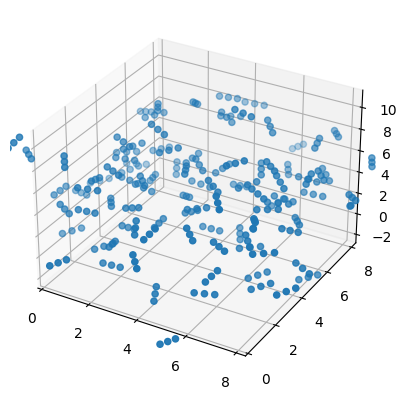

In [34]:
fig = plt.figure()
ax = plt.axes(projection='3d')
ax.scatter3D(pos[:,0], pos[:,1], pos[:,2])
# ax.scatter3D(pos_com[:,0], pos_com[:,1], pos_com[:,2],c='red',s=100)
plt.xlim(0,L)
plt.ylim(0,L)
plt.show()

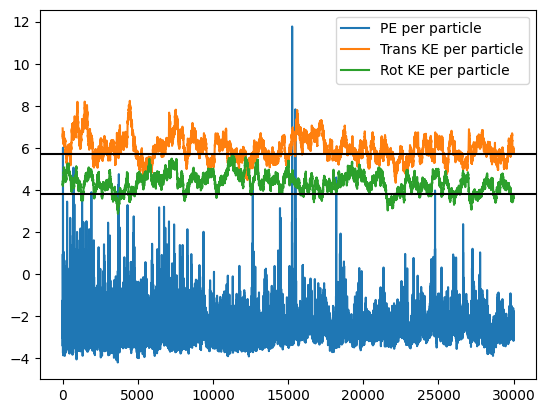

In [46]:
# print("Average Potential Energy = ", np.average(pe[total_timesteps//2::]))
# print("Average Kinetic Energy = ", np.average(ke[total_timesteps//2::]))

plt.plot(pe, label = "PE per particle")
# plt.plot(ke, label = "Kinetic Energy per particle")
# plt.plot(np.add(ke,pe), label = "Total Energy per particle")
plt.plot(ke_trans, label = "Trans KE per particle")
plt.plot(ke_rot, label = "Rot KE per particle")

plt.axhline(kBT,color='black')
plt.axhline(1.5*kBT,color='black')

# plt.ylim(-4, 10)
plt.legend()
# plt.grid()
plt.show()

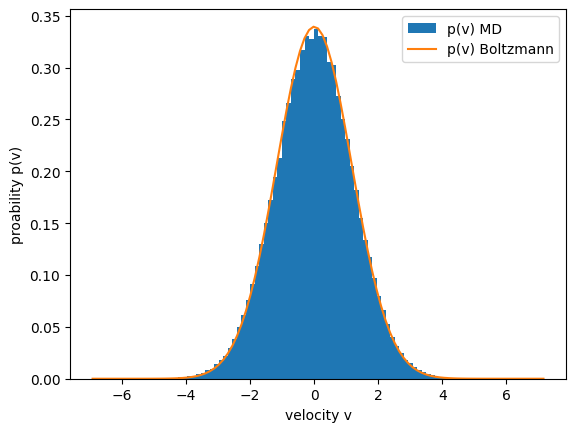

In [36]:
#Velocity Distribution and Potential Energy Distribution

nb = 100 # number of bins
counts, bins = np.histogram(vel_every_20, density=True, bins=nb)
plt.hist(bins[:-1], bins, weights=counts, label="p(v) MD") # plot histogram
plt.plot(bins, np.exp(-m/2 * (bins*bins)/kBT)/np.sqrt(2*np.pi*kBT/m),label="p(v) Boltzmann") # compare to Boltzmann distribution
plt.legend()
plt.xlabel("velocity v")
plt.ylabel("proability p(v)")
plt.show()

# If the simulated histogram matches the Boltzman prediction, then our MD algorithm works well and
# produces a statistically correct distribution of equilibrium states.

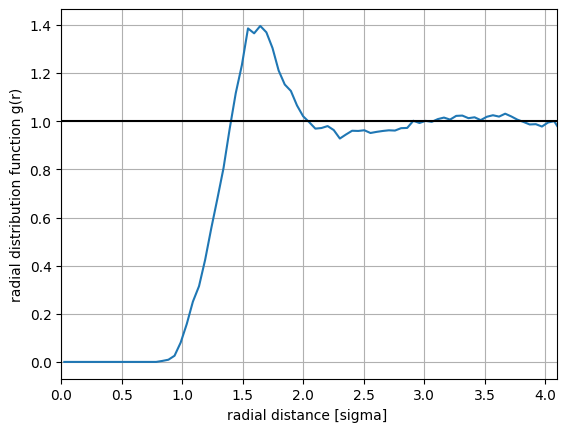

In [37]:
# plot radial distribution function
r = np.linspace(binwidth/2,0.5*L + binwidth/2,nbins) # create r vector to plot the radial distribution, r is centered on each bin
iter = (total_timesteps - start)/100
gr = gr_col / ((iter)*(num_particles/(L**3))*(num_particles/2)) # normalize the histogram (iter for time averaging & N/2 for particle average)
plt.plot(r, gr, label="g(r)")
plt.xlabel("radial distance [sigma] ")
plt.ylabel("radial distribution function g(r)")
plt.hlines(1, 0, L, colors='black')
plt.xlim(0,L/2)
plt.grid()
plt.show()

In [38]:
def calculate_msd(N, coord):
  cx = coord[:,0]
  cy = coord[:,1]
  cz = coord[:,2]

  msd = np.zeros(N-1)
  for i in range(1,N): # Considering 1 step movements to N-1 step movements
    for j in range(N-i):
      msd[i-1]+= ((cx[j+i]-cx[j])**2 + (cy[j+i]-cy[j])**2 + (cz[j+i]-cz[j])**2)

    msd[i-1]/=(N-i)
    
  return msd

In [39]:
msd = []
N = len(pos_com_every_20)
p = np.array(pos_com_every_20)
for i in range(num_particles):
  m = calculate_msd(N, p[:,i])
  msd.append(m)

t = [i*100*dt for i in range(N-1)]
msd_avg = np.mean(msd, axis=0)

Slope =  0.36327854853932295


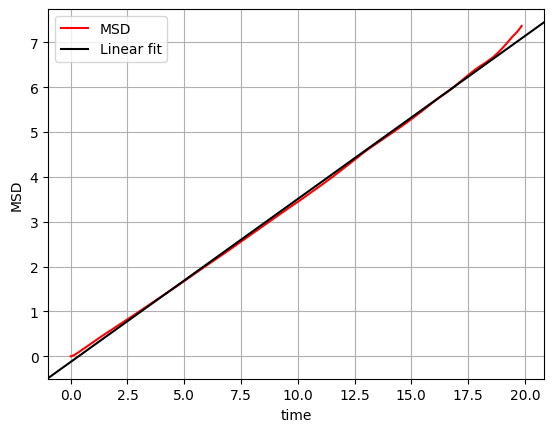

In [40]:
plt.plot(t,msd_avg, color='red', label='MSD')
plt.xlabel("time")
plt.ylabel("MSD")
plt.grid()


m,b = np.polyfit(t, msd_avg, 1)
plt.axline((0,b),slope=m, color='black', label='Linear fit')
print('Slope = ', m)
plt.legend()
plt.show()

In [42]:
# SAVE CONFIGURATION EVOLUTION
with open('RT_CO2_MD.xyz', 'w') as f:
  for i in range(len(pos_every_20)):
    f.write(str(num_units)+'\n')
    f.write("CO2 molecules\n")
    for j in range(num_particles):
      po1 = pos_every_20[i][3*j]
      pc = pos_every_20[i][3*j+1]
      po2 = pos_every_20[i][3*j+2]

      #periodic bc
      po1 = po1 - L*np.floor(po1/L)
      pc = pc - L*np.floor(pc/L)
      po2 = po2 - L*np.floor(po2/L)

      f.write('O ' + str(po1[0]) + ' ' + str(po1[1]) + ' ' + str(po1[2]) + '\n')
      f.write('C ' + str(pc[0]) + ' ' + str(pc[1]) + ' ' + str(pc[2]) + '\n')
      f.write('O ' + str(po2[0]) + ' ' + str(po2[1]) + ' ' + str(po2[2]) + '\n')

f.close()

In [41]:
#Check
for i in range(len(pos_every_20)):
  for j in range(num_particles):
    po1 = pos_every_20[i][3*j]
    pc = pos_every_20[i][3*j+1]
    po2 = pos_every_20[i][3*j+2]

    b1 = np.linalg.norm(po1-pc)
    b2 = np.linalg.norm(po2-pc)
    if round(b1, 2) != round(b2, 2): print(b1, b2)